In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd
df = pd.read_csv("StudentsPerformance.csv")

In [ ]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [ ]:
df.sample(5)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
217,female,group C,high school,free/reduced,none,34,42,39
975,female,group C,some college,standard,completed,64,82,77
505,female,group B,some high school,standard,none,82,82,80
11,male,group D,associate's degree,standard,none,40,52,43
960,female,group A,some college,standard,none,56,58,64


In [ ]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [ ]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [ ]:
df.dtypes

,0
gender,object
race/ethnicity,object
parental level of education,object
lunch,object
test preparation course,object
math score,int64
reading score,int64
writing score,int64


In [ ]:
df["Total_Score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
)

In [ ]:
df["Average_Score"] = df["Total_Score"] / 3

## Step 5: Label Encoding

**Objective:** Demonstrate label encoding using the sample dataset.

Label encoding is a technique used to convert categorical columns into a numerical format that can be easily understood by machine learning algorithms. I will apply `LabelEncoder` to the 'gender' and 'lunch' columns as an example.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a temporary copy of df to demonstrate label encoding
df_encoded = df.copy()

# Initialize LabelEncoder
le = LabelEncoder()

# Apply Label Encoding to 'gender' column
df_encoded['gender_encoded'] = le.fit_transform(df_encoded['gender'])
print(f"Original 'gender' unique values: {df_encoded['gender'].unique()}")
print(f"Encoded 'gender_encoded' unique values: {df_encoded['gender_encoded'].unique()}\n")

# Apply Label Encoding to 'lunch' column
df_encoded['lunch_encoded'] = le.fit_transform(df_encoded['lunch'])
print(f"Original 'lunch' unique values: {df_encoded['lunch'].unique()}")
print(f"Encoded 'lunch_encoded' unique values: {df_encoded['lunch_encoded'].unique()}\n")

print("DataFrame after Label Encoding (first 5 rows with new columns):")
display(df_encoded[['gender', 'gender_encoded', 'lunch', 'lunch_encoded']].head())

Original 'gender' unique values: ['female' 'male']
Encoded 'gender_encoded' unique values: [0 1]

Original 'lunch' unique values: ['standard' 'free/reduced']
Encoded 'lunch_encoded' unique values: [1 0]

DataFrame after Label Encoding (first 5 rows with new columns):


,gender,gender_encoded,lunch,lunch_encoded
0,female,0,standard,1
1,female,0,standard,1
2,female,0,standard,1
3,male,1,free/reduced,0
4,male,1,standard,1


## Step 6: Scaling

**Objective:** Demonstrate data scaling using the sample dataset.

Scaling is an important preprocessing step that transforms numerical features to a standard range. This helps prevent features with larger values from dominating algorithms that rely on distance calculations or gradient descent. We will demonstrate two common methods: StandardScaler and MinMaxScaler.

### 6.1 StandardScaler (Z-score normalization)

`StandardScaler` transforms features by subtracting the mean and scaling to unit variance. This results in data with a mean of 0 and a standard deviation of 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create a temporary copy of df for StandardScaler demonstration
df_scaled_standard = df.copy()

# Define numerical columns for scaling
numerical_cols = ['math score', 'reading score', 'writing score', 'Total_Score', 'Average_Score']

# Initialize StandardScaler
scaler = StandardScaler()

# Apply StandardScaler to numerical columns
df_scaled_standard[numerical_cols] = scaler.fit_transform(df_scaled_standard[numerical_cols])

print("DataFrame after StandardScaler (first 5 rows for numerical columns):")
display(df_scaled_standard[numerical_cols].head())

DataFrame after StandardScaler (first 5 rows for numerical columns):


,math score,reading score,writing score,Total_Score,Average_Score
0,0.390024,0.193999,0.391492,0.343574,0.343574
1,0.192076,1.427476,1.313269,1.021927,1.021927
2,1.577711,1.770109,1.642475,1.747064,1.747064
3,-1.259543,-0.833899,-1.583744,-1.293830,-1.293830
4,0.653954,0.605158,0.457333,0.600881,0.600881


## Step 7: Feature Selection

**Objective:** Demonstrate feature selection using the sample dataset.

Feature selection is the process of selecting a subset of relevant features for use in model construction. It helps in reducing overfitting, improving model accuracy, and reducing training time. We will demonstrate two methods: correlation-based selection and Chi-squared test.

### 7.2 Chi-squared Test (for Categorical Features)

For categorical features, the Chi-squared test can be used to determine if there is a significant relationship between two categorical variables. A higher Chi-squared statistic and a lower p-value indicate a stronger relationship. Here we will test the relationship between encoded categorical features and the `Performance` variable.

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import LabelEncoder
import pandas as pd # Ensure pandas is imported

# Create a copy of the original DataFrame to avoid modifying 'df'
df_chi2 = df.copy()

# Re-create 'Total_Score' and 'Average_Score' as these are upstream dependencies for 'Average_Score_Category'
df_chi2["Total_Score"] = df_chi2["math score"] + df_chi2["reading score"] + df_chi2["writing score"]
df_chi2["Average_Score"] = df_chi2["Total_Score"] / 3

# Discretize 'Average_Score' to create 'Average_Score_Category'
bins = [0, 40, 60, 80, 100]
labels = ['Poor', 'Average', 'Good', 'Excellent']
df_chi2['Average_Score_Category'] = pd.cut(
    df_chi2['Average_Score'],
    bins=bins,
    labels=labels,
    right=False
)

# Define categorical columns to encode for the Chi-squared test
categorical_cols_to_encode = [
    'gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course'
]

# Encode all categorical features and store their encoded column names
encoded_categorical_features_for_chi2 = []
le = LabelEncoder()
for col in categorical_cols_to_encode:
    df_chi2[f'{col}_encoded'] = le.fit_transform(df_chi2[col])
    encoded_categorical_features_for_chi2.append(f'{col}_encoded')

# Encode the target variable 'Average_Score_Category'
le_performance_cat = LabelEncoder()
df_chi2['Average_Score_Category_encoded'] = le_performance_cat.fit_transform(df_chi2['Average_Score_Category'])

# Prepare features (X) and target (y) for the Chi-squared test
X = df_chi2[encoded_categorical_features_for_chi2]
y = df_chi2['Average_Score_Category_encoded']

# Apply SelectKBest with chi2 to find the best features
bestfeatures = SelectKBest(score_func=chi2, k='all')
fit = bestfeatures.fit(X, y)

dfscores = pd.DataFrame(fit.scores_)
dfcolumns = pd.DataFrame(X.columns)

# Concat two dataframes for better visualization
feature_scores = pd.concat([dfcolumns, dfscores], axis=1)
feature_scores.columns = ['Feature', 'Score']
feature_scores.sort_values(by=['Score'], ascending=False, inplace=True)

print("Chi-squared scores for categorical features against Performance:")
display(feature_scores)

Chi-squared scores for categorical features against Performance:


,Feature,Score
3,lunch_encoded,28.543209
4,test preparation course_encoded,20.862750
1,race/ethnicity_encoded,19.009011
2,parental level of education_encoded,11.434486
0,gender_encoded,7.533882


## Step 7: Feature Selection

**Objective:** Demonstrate feature selection using the sample dataset.

Feature selection is the process of selecting a subset of relevant features for use in model construction. It helps in reducing overfitting, improving model accuracy, and reducing training time. We will demonstrate two methods: correlation-based selection and Chi-squared test.

### 7.1 Correlation-based Feature Selection (for Numerical Features)

We will examine the correlation of numerical features with the `Average_Score` (our target here) to understand their predictive power. Features with high absolute correlation values are generally considered more relevant.

In [ ]:
# Using df_encoded as it contains both original numerical columns and encoded categorical ones
numerical_features_for_correlation = ['math score', 'reading score', 'writing score', 'Total_Score', 'Average_Score']

# Calculate correlation with Average_Score
correlations = df_encoded[numerical_features_for_correlation].corr()['Average_Score'].sort_values(ascending=False)

print("Correlation of numerical features with Average_Score:")
display(correlations)

Correlation of numerical features with Average_Score:


,Average_Score
Average_Score,1.000000
Total_Score,1.000000
reading score,0.970331
writing score,0.965667
math score,0.918746


## Step 8: Feature Extraction (PCA)

**Objective:** Demonstrate feature extraction using Principal Component Analysis (PCA).

Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms a set of correlated variables into a smaller number of uncorrelated variables called principal components. These new features capture the most variance in the data, allowing for more efficient modeling and sometimes improved performance by reducing noise and multicollinearity.

In [ ]:
from sklearn.preprocessing import StandardScaler # PCA is sensitive to scale, so we'll scale first
from sklearn.decomposition import PCA

# Select numerical columns for PCA. Let's use the original scores and total/average for this demo.
# It's important to use the scaled data for PCA.
pca_numerical_cols = ['math score', 'reading score', 'writing score', 'Total_Score', 'Average_Score']

# Create a temporary copy of df for PCA demonstration
df_pca = df.copy()

# Scale the numerical data before applying PCA
scaler_pca = StandardScaler()
df_pca[pca_numerical_cols] = scaler_pca.fit_transform(df_pca[pca_numerical_cols])

# Initialize PCA. Let's start by retaining all components to see their explained variance.
pca = PCA(n_components=len(pca_numerical_cols))

# Fit PCA on the scaled numerical features
principal_components = pca.fit_transform(df_pca[pca_numerical_cols])

# Create a DataFrame for the principal components
df_principal_components = pd.DataFrame(data = principal_components,
                                       columns = [f'PC_{i+1}' for i in range(len(pca_numerical_cols))])

print("Principal Components (first 5 rows):")
display(df_principal_components.head())

print("\nExplained variance ratio for each principal component:")
display(pd.DataFrame({'Principal Component': [f'PC_{i+1}' for i in range(len(pca_numerical_cols))],
                      'Explained Variance Ratio': pca.explained_variance_ratio_}))

print("\nCumulative Explained Variance Ratio:", pca.explained_variance_ratio_.sum())

Principal Components (first 5 rows):


,PC_1,PC_2,PC_3,PC_4,PC_5
0,0.741893,0.087596,-0.145011,-7.033482e-16,1.385123e-15
1,2.244895,-0.913336,0.119123,2.109056e-15,-6.769719e-16
2,3.796929,-0.025945,0.085446,1.138499e-15,-5.252238e-16
3,-2.800488,-0.072326,0.538620,3.200597e-15,-4.616511e-15
4,1.303368,0.130572,0.096564,2.265645e-16,-1.108255e-15



Explained variance ratio for each principal component:


,Principal Component,Explained Variance Ratio
0,PC_1,0.943661
1,PC_2,0.047341
2,PC_3,0.008999
3,PC_4,0.000000
4,PC_5,0.000000



Cumulative Explained Variance Ratio: 0.9999999999999999


## Step 10: Data Discretization

**Objective:** Demonstrate data discretization using the sample dataset.

Data discretization (also known as binning) is the process of transforming continuous numerical features into discrete, categorical bins. This can help to simplify the model, handle outliers, and make the data more interpretable. We will use `pd.cut` to discretize the `Average_Score` into new performance categories.

Original 'Average_Score' distribution (first 5 rows):


,Average_Score
0,72.666667
1,82.333333
2,92.666667
3,49.333333
4,76.333333



DataFrame after Discretization (first 5 rows with new category column):


,Average_Score,Average_Score_Category
0,72.666667,Good
1,82.333333,Excellent
2,92.666667,Excellent
3,49.333333,Average
4,76.333333,Good



Value counts for the new 'Average_Score_Category' column:


,count
Average_Score_Category,
Good,517
Average,255
Excellent,195
Poor,30


/tmp/ipykernel_1288/1329846658.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Average_Score_Category', data=df_discretized, order=labels, palette='viridis')


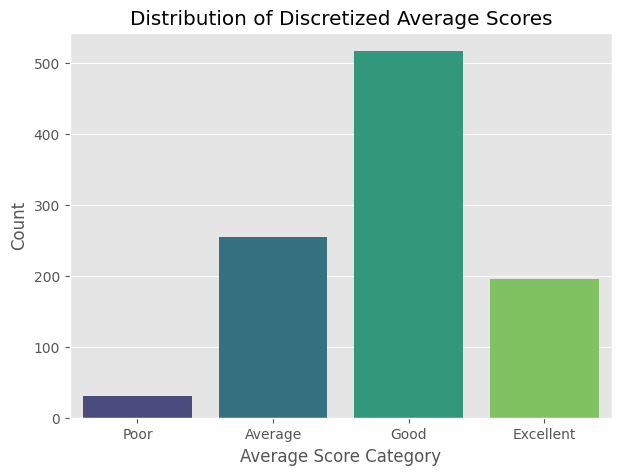

In [ ]:
# Create a temporary copy of df for discretization demonstration
df_discretized = df.copy()

# Define bins and labels for discretization of 'Average_Score'
bins = [0, 40, 60, 80, 100]  # Define the boundaries for the bins
labels = ['Poor', 'Average', 'Good', 'Excellent'] # Labels for the new categories

# Apply pd.cut to discretize 'Average_Score'
df_discretized['Average_Score_Category'] = pd.cut(
    df_discretized['Average_Score'],
    bins=bins,
    labels=labels,
    right=False # right=False means the bins are [a, b) (inclusive of left, exclusive of right)
)

print("Original 'Average_Score' distribution (first 5 rows):")
display(df_discretized[['Average_Score']].head())

print("\nDataFrame after Discretization (first 5 rows with new category column):")
display(df_discretized[['Average_Score', 'Average_Score_Category']].head())

print("\nValue counts for the new 'Average_Score_Category' column:")
display(df_discretized['Average_Score_Category'].value_counts())

# Visualize the distribution of the new categories
plt.figure(figsize=(7, 5))
sns.countplot(x='Average_Score_Category', data=df_discretized, order=labels, palette='viridis')
plt.title('Distribution of Discretized Average Scores')
plt.xlabel('Average Score Category')
plt.ylabel('Count')
plt.show()

## Step 13: Data Reduction

**Objective:** Demonstrate data reduction using the sample dataset.

Data reduction aims to decrease the volume of data while producing the same or similar analytical results. It can involve various techniques such as dimensionality reduction (e.g., PCA), numerosity reduction (e.g., aggregation, sampling), and data compression. As we've covered PCA and feature selection previously, here we will demonstrate **numerosity reduction through aggregation**. We will group the data by a combination of categorical features and compute the mean of the numerical scores, thereby reducing the number of individual records into summarized groups.

In [ ]:
# Create a temporary copy of df for data reduction demonstration
df_reduced = df.copy()

# Define columns to group by for aggregation
grouping_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

# Define numerical columns to aggregate
numerical_cols_to_aggregate = ['math score', 'reading score', 'writing score', 'Total_Score', 'Average_Score']

# Perform aggregation: group by selected columns and calculate the mean of numerical scores
df_aggregated = df_reduced.groupby(grouping_cols)[numerical_cols_to_aggregate].mean().reset_index()

print("Original DataFrame shape:", df.shape)
print("Reduced (Aggregated) DataFrame shape:", df_aggregated.shape)

print("\nFirst 5 rows of the Original DataFrame:")
display(df.head())

print("\nFirst 5 rows of the Reduced (Aggregated) DataFrame:")
display(df_aggregated.head())

print("\nValue counts for 'gender' in original vs aggregated data:")
print("Original:")
display(df['gender'].value_counts())
print("Aggregated:")
display(df_aggregated['gender'].value_counts())

Original DataFrame shape: (1000, 10)
Reduced (Aggregated) DataFrame shape: (211, 10)

First 5 rows of the Original DataFrame:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total_Score,Average_Score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333



First 5 rows of the Reduced (Aggregated) DataFrame:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total_Score,Average_Score
0,female,group A,associate's degree,free/reduced,none,47.666667,64.333333,60.000000,172.000000,57.333333
1,female,group A,associate's degree,standard,completed,60.000000,67.500000,68.000000,195.500000,65.166667
2,female,group A,associate's degree,standard,none,82.000000,93.000000,93.000000,268.000000,89.333333
3,female,group A,bachelor's degree,standard,none,51.666667,60.000000,61.666667,173.333333,57.777778
4,female,group A,high school,free/reduced,completed,54.666667,62.000000,62.000000,178.666667,59.555556



Value counts for 'gender' in original vs aggregated data:
Original:


,count
gender,
female,518
male,482


Aggregated:


,count
gender,
female,106
male,105


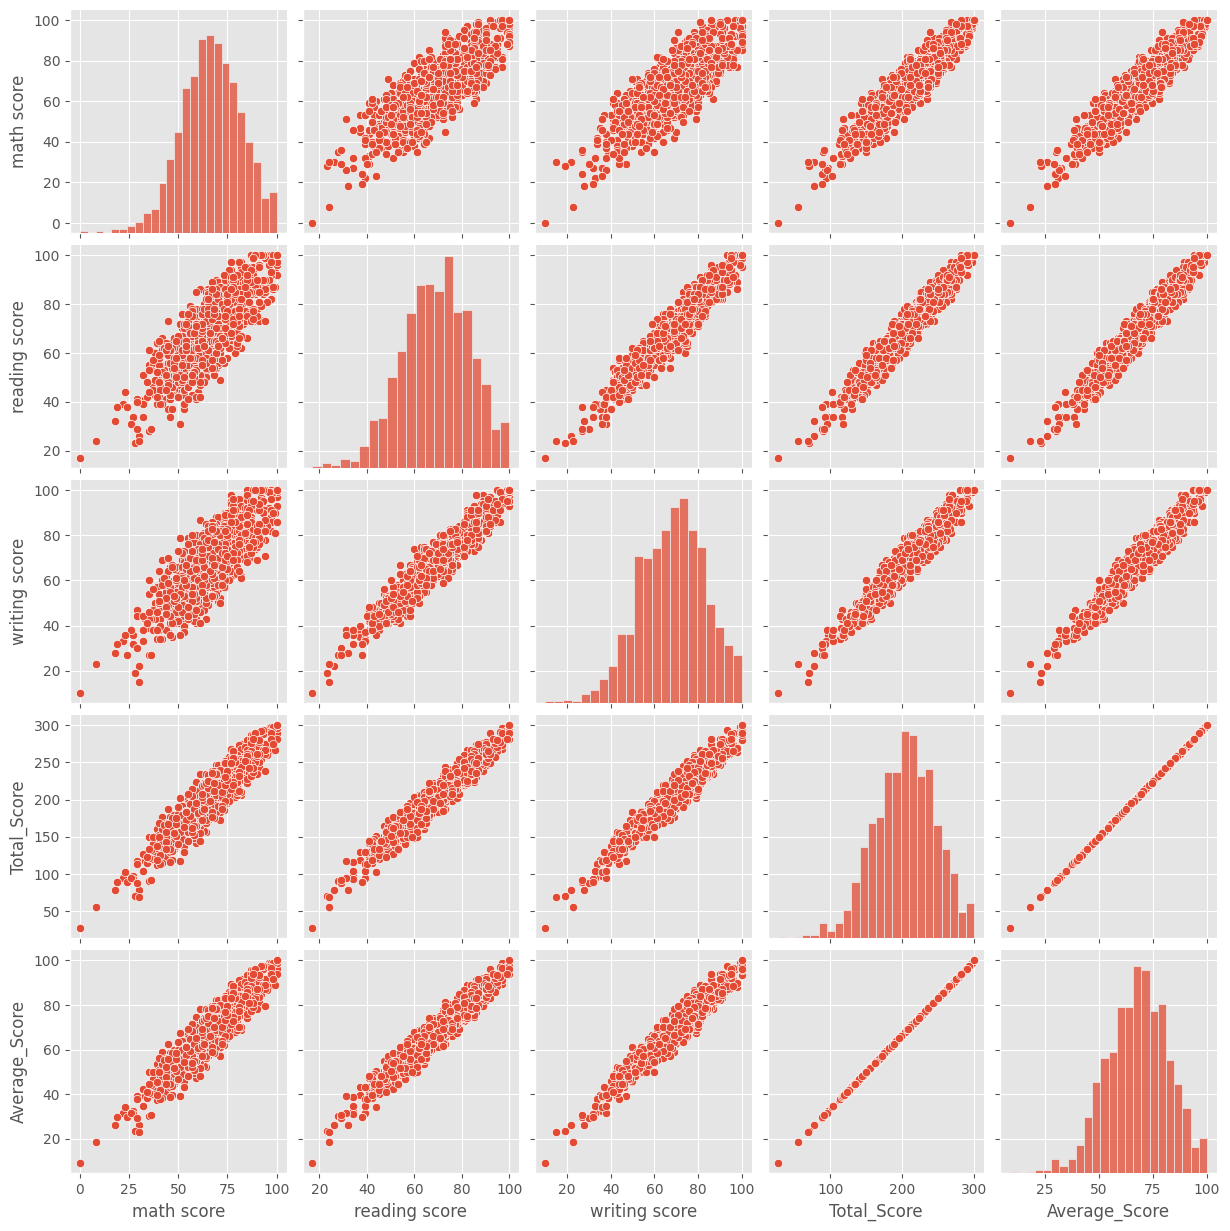

In [ ]:
sns.pairplot(df)

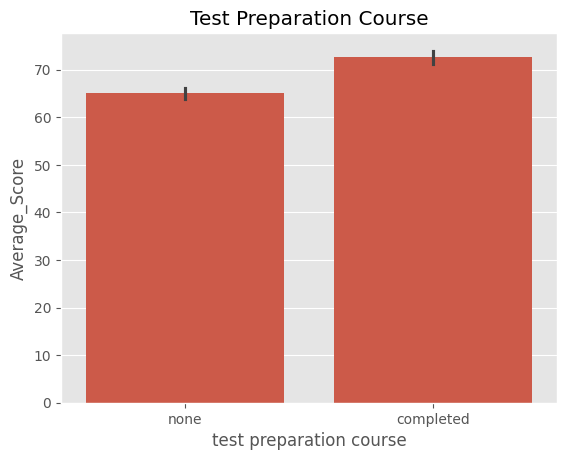

In [ ]:
sns.barplot(x="test preparation course", y="Average_Score", data=df)
plt.title("Test Preparation Course")
plt.show()

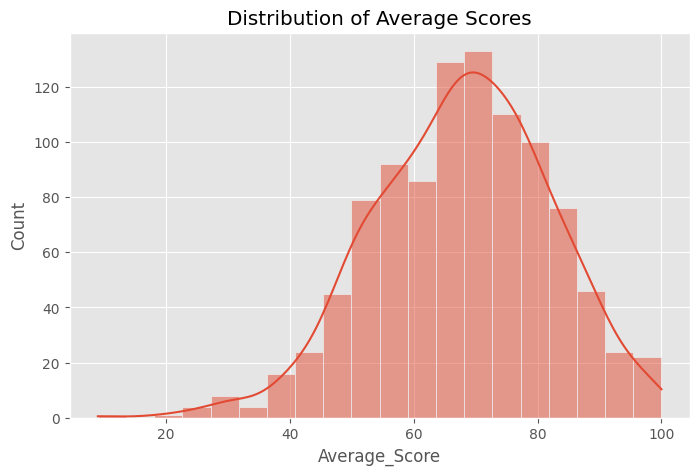

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["Average_Score"], bins=20, kde=True)
plt.title("Distribution of Average Scores")
plt.show()

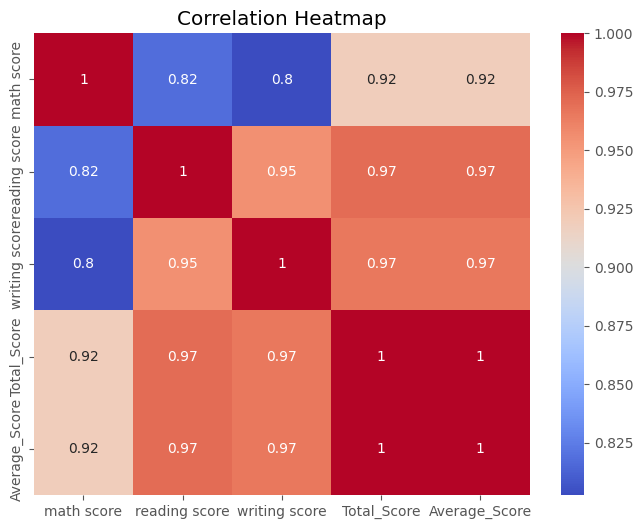

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

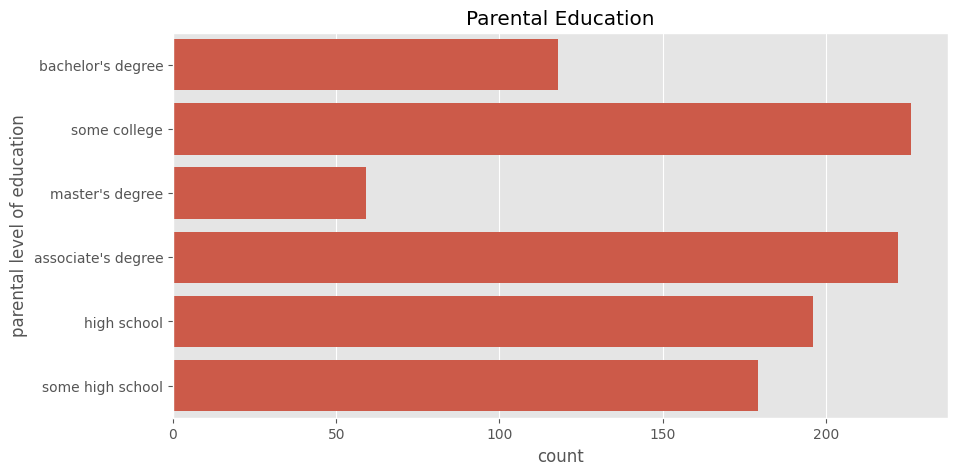

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(y="parental level of education", data=df)
plt.title("Parental Education")
plt.show()

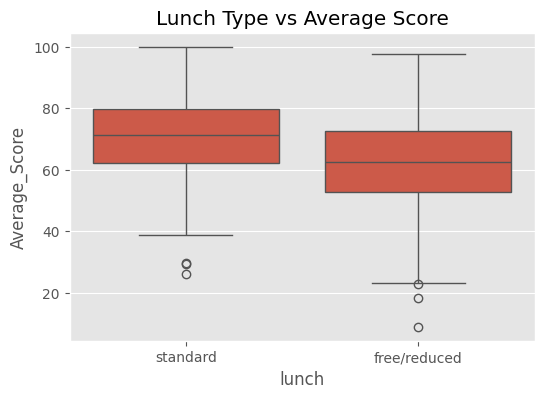

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x="lunch", y="Average_Score", data=df)
plt.title("Lunch Type vs Average Score")
plt.show()

## Step 14: Save as CSV File

**Objective:** Demonstrate saving the processed data into a CSV file.

After performing various preprocessing steps, it's often necessary to save the cleaned and transformed data for future use. We'll save the original `df` and the `df_aggregated` DataFrame (from data reduction) as separate CSV files. This also shows how to download the files if needed.

In [ ]:
# Save the original DataFrame 'df' to a new CSV file
df.to_csv('students_performance_original_with_features.csv', index=False)
print("Original DataFrame saved as 'students_performance_original_with_features.csv'")

# Save the aggregated DataFrame 'df_aggregated' to a new CSV file
df_aggregated.to_csv('students_performance_aggregated.csv', index=False)
print("Aggregated DataFrame saved as 'students_performance_aggregated.csv'")

Original DataFrame saved as 'students_performance_original_with_features.csv'
Aggregated DataFrame saved as 'students_performance_aggregated.csv'


In [ ]:
from google.colab import files

# Download the original DataFrame CSV
files.download('students_performance_original_with_features.csv')

# Download the aggregated DataFrame CSV
files.download('students_performance_aggregated.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

                       Model  Test R2    MAE   RMSE  5-fold CV R2
Linear Regression (baseline)    0.178 10.389 13.278         0.215
               Random Forest    0.127 10.674 13.679         0.165


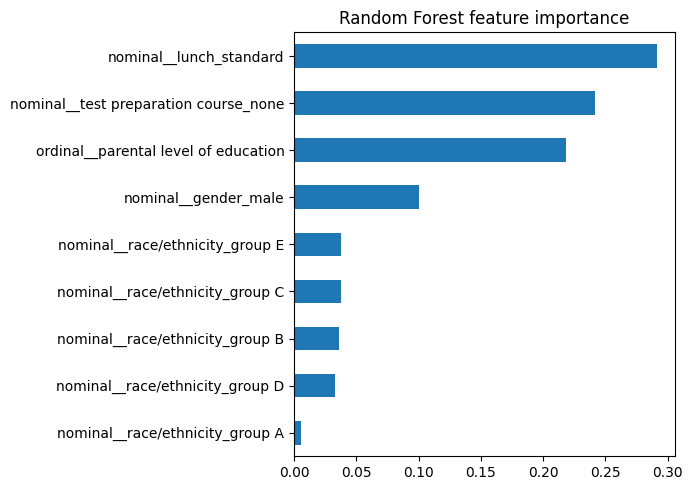

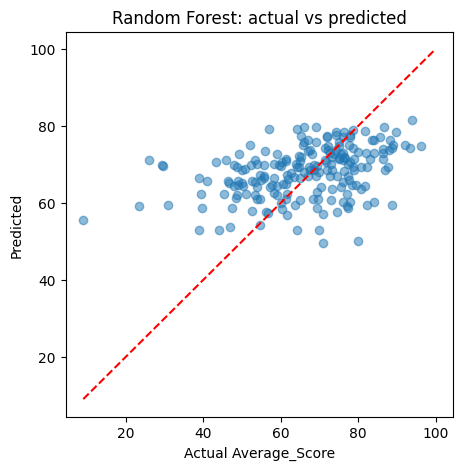

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---------- 1. Data ----------
df = pd.read_csv("StudentsPerformance.csv")
df["Average_Score"] = df[["math score", "reading score", "writing score"]].mean(axis=1)

nominal_cols = ["gender", "race/ethnicity", "lunch", "test preparation course"]
ordinal_col = ["parental level of education"]
edu_order = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]

# Only categorical features -> no leakage from the score columns
X = df[nominal_cols + ordinal_col]
y = df["Average_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- 2. Preprocessing ----------
preprocess = ColumnTransformer([
    ("nominal", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), nominal_cols),
    ("ordinal", OrdinalEncoder(categories=[edu_order]), ordinal_col),
])

# ---------- 3. Models ----------
models = {
    "Linear Regression (baseline)": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=10, random_state=42
    ),
}

pipes = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring="r2").mean()
    rows.append({
        "Model": name,
        "Test R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "5-fold CV R2": cv_r2,
    })
    pipes[name] = pipe

print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---------- 4. Feature importance (Random Forest) ----------
rf_pipe = pipes["Random Forest"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
imp.sort_values().plot(kind="barh", figsize=(7, 5), title="Random Forest feature importance")
plt.tight_layout()
plt.show()

# ---------- 5. Actual vs predicted ----------
pred_rf = rf_pipe.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_rf, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Average_Score")
plt.ylabel("Predicted")
plt.title("Random Forest: actual vs predicted")
plt.show()